# ColheAí — Risco de descumprir a meta da agricultura familiar no PNAE

## Global Solution 2026/2 · CitizenTech · Artificial Intelligence & Chatbot

**Since Young · Turma 1TDSPV-2026 · FIAP — Análise e Desenvolvimento de Sistemas**
Professor: Alfonso José Trindade Rodriguez

| Integrante | RM |
|---|---|
| **Artur Bianchini Esteves** | **RM569450** — representante |
| João Vitor Oliveira Fontenele Martins | RM570783 |

---

### O que este notebook entrega

| Item da rubrica (IA, 100 pts) | Onde está |
|---|---|
| 01 Dados usados no treino (10) | Seção 2 + pasta `dados/` (base bruta e normalizada) |
| 02 Notebook: EDA, treinamento e avaliação (60) | Seções 3 a 11 |
| 03 Modelos pré-treinados (10) | Seção 12 → `modelos/modelo_risco_meta.joblib` e `modelos/modelo_perfil_kmeans.joblib` |
| 04 API Flask e integração (20) | Seção 13 → `api/api_colheai_ia.py` |

**Dois modelos, de tipos diferentes**, como pede o edital (*regressão, classificação e/ou agrupamento*):

1. **Classificação** — risco de o município ficar abaixo da meta de compra da agricultura familiar (Regressão Logística, comparada com um Random Forest).
2. **Agrupamento (K-Means)** — perfis dos 645 municípios paulistas, que viram a lista de clientes-alvo do ColheAí.

**Todos os dados são públicos e reais** (FNDE e IBGE). Nada foi simulado.

---
## 1. O problema

Todo município recebe do FNDE o repasse do **PNAE** (a merenda escolar) e é obrigado a gastar uma parte
dele comprando **direto da agricultura familiar**. Até 2025 o mínimo era **30%**. A **Lei 15.226/2025**
subiu para **45% a partir de 2026**.

O problema é que muita prefeitura não cumpria nem os 30%. A própria cidade de São Paulo ficou em 26,2% (2018)
e 26,8% (2019) segundo auditoria do TCM-SP, com chamadas públicas fracassadas e sem mapeamento da oferta local.

**Onde a IA entra no ColheAí.** A Aula 11 (Stack de IA) chama isso de *inteligência acionável preditiva*:
em vez de descobrir no fim do ano que a meta não foi cumprida, a prefeitura (EEx, Entidade Executora)
recebe **antes** um alerta de risco, e o ColheAí sabe **para quais municípios** vender e com qual discurso.

| Pergunta de negócio | Modelo | Saída na API |
|---|---|---|
| "Este município corre risco de não cumprir a meta?" | Classificação | probabilidade + faixa de risco |
| "Que tipo de município é este e como abordá-lo?" | K-Means | perfil + recomendação comercial |

A ligação com o banco de dados da solução é o **código IBGE do município** (`cd_ibge_municipio` na tabela
`T_CLH_ENTIDADE_EXECUTORA`): São Paulo 3550308, Embu-Guaçu 3515103, Itapecerica da Serra 3522208.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_recall_fscore_support, roc_auc_score,
                             roc_curve, silhouette_score)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split

SEMENTE = 42                      # garante resultado reproduzivel
PASTA_DADOS = '../dados'
PASTA_MODELOS = '../modelos'
PASTA_FIGURAS = 'figuras'
os.makedirs(PASTA_MODELOS, exist_ok=True)
os.makedirs(PASTA_FIGURAS, exist_ok=True)

# Cores da identidade visual do ColheAi (claude/identidade-visual.md)
VERDE = '#2F7A57'      # Verde horta - 1a serie: CUMPRIU a meta
GRAFITE = '#5A6672'    # Grafite     - 2a serie: ABAIXO da meta (risco)
MILHO = '#A88424'      # Milho escuro - 3a serie / destaque
COR_CLASSE = {0: VERDE, 1: GRAFITE}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'figure.dpi': 110})

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| numpy', np.__version__)

scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3


---
## 2. A base de dados

### 2.1 De onde vieram os dados (todos públicos, acesso em 17/11/2026)

| Fonte | O que traz | Arquivo |
|---|---|---|
| **FNDE — PNAE: Dados da Agricultura Familiar** (2011 a 2022) | por município e ano: valor transferido pelo FNDE e valor comprado da agricultura familiar | `fnde_pnae_agricultura_familiar_sp_2011_2022.csv` |
| **IBGE — Censo 2022** (SIDRA 4714 e 9923) | população, área, densidade, população rural | `municipios_sp_base_bruta.csv` |
| **IBGE — PIB dos Municípios 2021** (SIDRA 5938 e 6579) | PIB per capita | idem |
| **IBGE — Censo Agropecuário 2017** (SIDRA 6778) | estabelecimentos da agricultura familiar | idem |
| **IBGE — API de localidades** | região geográfica intermediária | idem |

### 2.2 Como os dados do FNDE foram obtidos

O FNDE **não oferece arquivo para download**: publica os dados só num painel Power BI público. O painel,
porém, consulta uma API pública do Power BI (é o que o navegador faz ao abrir a página). O script
`dados/coleta_dados_publicos.py` faz essa mesma consulta, filtra **UF = SP** e esfera **municipal**
e grava o CSV. Rodar o script de novo baixa os mesmos dados.

### 2.3 Problemas de qualidade encontrados (e o que fizemos)

| Problema | Tratamento |
|---|---|
| **94 linhas com o código IBGE de um município homônimo de outro estado** (ex.: Tabatinga-SP vinha com o código de Tabatinga-AM) | código recuperado pelo nome na lista oficial do IBGE; linha marcada com `st_codigo_ibge_corrigido = S` |
| **2022 é preliminar** (o próprio FNDE avisa) e tem 36 municípios acima de 100% | 2022 **não entra no treino**; é usado só como teste fora do tempo (seção 10) |
| **2020 e 2021 são anos de pandemia** (escolas fechadas, compra atípica: mediana de 5% a 9%) | ficam fora do rótulo |
| Percentual acima de 100% (comprou mais que o repasse) | limitado a 100%, como faz o MonitoraSAN/Consea |
| No SIDRA, "-" significa **zero absoluto** | lido como 0, não como ausente |

### 2.4 Padronização dos CSV (retorno da Sprint 3: *"Arquivos csv sem nenhuma padronização"*)

Categóricos em MAIÚSCULA sem acento e com `_`; casas decimais fixas por coluna; ponto decimal; vírgula
separando campos; UTF-8; ausência sempre como **célula vazia**; prefixos de coluna do padrão do banco
(`cd_`, `nm_`, `qt_`, `vl_`, `pc_`, `st_`). Entregamos a **base bruta** e a **base normalizada (0 a 1)**.

In [2]:
fnde = pd.read_csv(os.path.join(PASTA_DADOS, 'fnde_pnae_agricultura_familiar_sp_2011_2022.csv'))
base = pd.read_csv(os.path.join(PASTA_DADOS, 'municipios_sp_base_bruta.csv'))

print('FNDE (municipio x ano): {} linhas x {} colunas | anos {} a {}'.format(
    *fnde.shape, fnde['ano'].min(), fnde['ano'].max()))
print('  codigos IBGE corrigidos (homonimos): {}'.format(
    int((fnde['st_codigo_ibge_corrigido'] == 'S').sum())))
print('Base por municipio: {} linhas x {} colunas'.format(*base.shape))
print('  municipios de SP no IBGE: 645 | na base: {}'.format(base['cd_ibge_municipio'].nunique()))
print()
print('Municipios do banco do ColheAi (T_CLH_ENTIDADE_EXECUTORA):')
print(base.loc[base['cd_ibge_municipio'].isin([3550308, 3515103, 3522208]),
               ['cd_ibge_municipio', 'nm_municipio', 'qt_populacao_2022',
                'pc_aquisicao_af_media_2014_2016', 'pc_aquisicao_af_media_2017_2019']].to_string(index=False))

FNDE (municipio x ano): 7396 linhas x 7 colunas | anos 2011 a 2022
  codigos IBGE corrigidos (homonimos): 94
Base por municipio: 645 linhas x 22 colunas
  municipios de SP no IBGE: 645 | na base: 645

Municipios do banco do ColheAi (T_CLH_ENTIDADE_EXECUTORA):
 cd_ibge_municipio         nm_municipio  qt_populacao_2022  pc_aquisicao_af_media_2014_2016  pc_aquisicao_af_media_2017_2019
           3515103           EMBU_GUACU              66970                             0.00                            22.88
           3522208 ITAPECERICA_DA_SERRA             158522                            18.44                            35.33
           3550308            SAO_PAULO           11451999                            14.55                            28.21


In [3]:
base.head(3)

,cd_ibge_municipio,nm_municipio,nm_regiao_intermediaria,qt_populacao_2022,vl_area_km2,vl_densidade_hab_km2,qt_populacao_rural_2022,pc_populacao_rural_2022,vl_pib_per_capita_2021,qt_estab_agro_total_2017,qt_estab_agro_familiar_2017,qt_estab_af_por_mil_hab,vl_transferido_medio_2014_2016,pc_aquisicao_af_media_2014_2016,qt_anos_sem_compra_af_2014_2016,qt_anos_cumpriu_30_2011_2016,vl_transferido_medio_2017_2019,pc_aquisicao_af_media_2017_2019,qt_anos_sem_compra_af_2017_2019,qt_anos_cumpriu_30_2014_2019,st_abaixo_meta_30_2017_2019,pc_aquisicao_af_2022_preliminar
0,3500105,ADAMANTINA,PRESIDENTE_PRUDENTE,34687,411.987,84.19,1151,3.32,38997.13,529.0,360.0,10.379,431318.33,53.68,0,4,551653.33,44.76,0,5,0.0,48.74
1,3500204,ADOLFO,SAO_JOSE_DO_RIO_PRETO,4351,211.055,20.62,346,7.95,32578.28,82.0,62.0,14.250,54362.00,0.00,2,0,NaN,NaN,0,0,NaN,NaN
2,3500303,AGUAI,CAMPINAS,32072,474.554,67.58,2177,6.79,35551.69,507.0,368.0,11.474,537195.00,23.69,0,2,634064.67,38.37,0,4,0.0,37.90


### 2.5 Como a pergunta virou um rótulo (desenho temporal)

O modelo precisa **prever o futuro a partir do passado**, então os dados foram organizados em duas
janelas de três anos:

| Janela | Anos | Papel no treino | Papel na API (uso real) |
|---|---|---|---|
| A | 2014–2016 | **entrada** (histórico de compra) | — |
| B | 2017–2019 | **rótulo**: média abaixo de 30%? | **entrada** para pontuar o próximo período |

**Rótulo:** `st_abaixo_meta_30_2017_2019 = 1` se a média de compra da agricultura familiar em 2017–2019
ficou abaixo de 30%. 2017–2019 são os três últimos anos consolidados antes da pandemia.

**Por que 30% e não 45%?** Porque 30% era a meta legal **naquele período**: é o que mede se o município
cumpria a regra. Com 45% o rótulo ficaria 85% positivo e o modelo teria pouco a aprender. Quem não
chegava a 30% é, com folga, quem mais corre risco diante dos 45% de agora. A API traduz isso na mensagem.

---
## 3. Análise exploratória

Cada gráfico responde a uma pergunta. Cores fixas: **verde = cumpriu**, **grafite = abaixo da meta**.

In [4]:
alvo = base['st_abaixo_meta_30_2017_2019']
contagem = alvo.value_counts().sort_index()
print('Municipios com rotulo: {} (1 sem dado do FNDE em 2017-2019 fica de fora)'.format(int(alvo.notna().sum())))
print('  cumpriu 30% (0) ........ {:3d}  ({:.1f}%)'.format(int(contagem[0]), 100 * contagem[0] / contagem.sum()))
print('  abaixo de 30% (1) ...... {:3d}  ({:.1f}%)'.format(int(contagem[1]), 100 * contagem[1] / contagem.sum()))
print()
print('Classes quase equilibradas: um modelo que chutasse sempre "abaixo" acertaria {:.1f}%.'.format(
    100 * contagem[1] / contagem.sum()))
print('Esse e o piso que qualquer modelo precisa superar - e por isso avaliamos F1 e AUC, nao acuracia.')

Municipios com rotulo: 644 (1 sem dado do FNDE em 2017-2019 fica de fora)
  cumpriu 30% (0) ........ 291  (45.2%)
  abaixo de 30% (1) ...... 353  (54.8%)

Classes quase equilibradas: um modelo que chutasse sempre "abaixo" acertaria 54.8%.
Esse e o piso que qualquer modelo precisa superar - e por isso avaliamos F1 e AUC, nao acuracia.


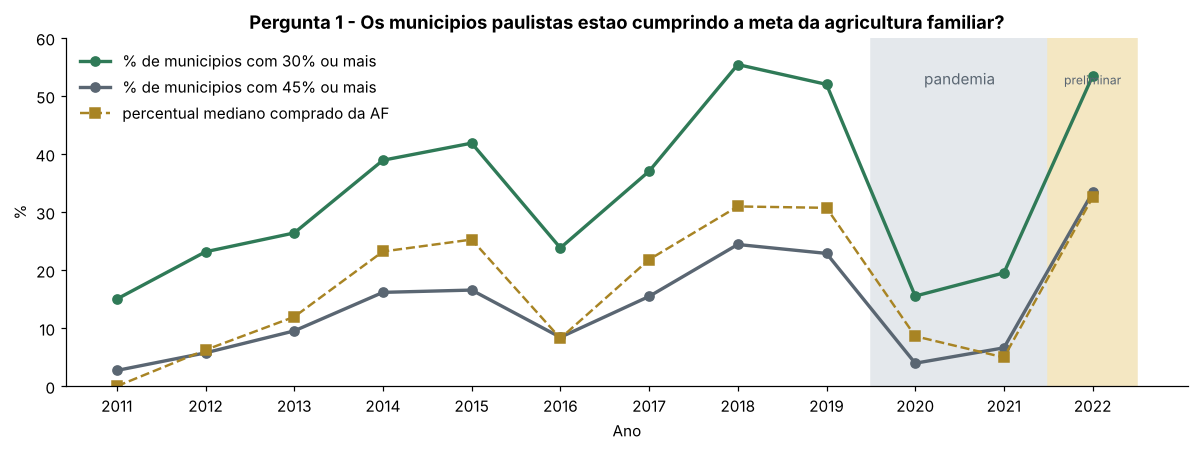

      mediana  cumpriu30  cumpriu45
ano                                
2011      0.0       15.0        2.7
2012      6.2       23.2        5.8
2013     12.0       26.4        9.5
2014     23.2       38.9       16.2
2015     25.3       41.9       16.6
2016      8.2       23.8        8.4
2017     21.8       37.0       15.5
2018     31.0       55.4       24.4
2019     30.7       52.0       22.9
2020      8.6       15.5        4.0
2021      5.0       19.5        6.6
2022     32.5       53.5       33.4


In [5]:
# Pergunta 1: o estado de SP esta melhorando ao longo do tempo?
fnde['pc_limitado'] = fnde['pc_aquisicao_af'].clip(upper=100)
por_ano = fnde.groupby('ano').agg(mediana=('pc_limitado', 'median'),
                                  cumpriu30=('pc_limitado', lambda s: 100 * (s >= 30).mean()),
                                  cumpriu45=('pc_limitado', lambda s: 100 * (s >= 45).mean()))

fig, eixo = plt.subplots(figsize=(11, 4.2))
eixo.plot(por_ano.index, por_ano['cumpriu30'], marker='o', color=VERDE, lw=2.2, label='% de municipios com 30% ou mais')
eixo.plot(por_ano.index, por_ano['cumpriu45'], marker='o', color=GRAFITE, lw=2.2, label='% de municipios com 45% ou mais')
eixo.plot(por_ano.index, por_ano['mediana'], marker='s', color=MILHO, lw=1.6, ls='--', label='percentual mediano comprado da AF')
eixo.axvspan(2019.5, 2021.5, color='#E4E8EC', zorder=0)
eixo.text(2020.5, 52, 'pandemia', ha='center', color=GRAFITE)
eixo.axvspan(2021.5, 2022.5, color='#F4E7C2', zorder=0)
eixo.text(2022, 52, 'preliminar', ha='center', color=GRAFITE, fontsize=8)
eixo.set_title('Pergunta 1 - Os municipios paulistas estao cumprindo a meta da agricultura familiar?')
eixo.set_xlabel('Ano'); eixo.set_ylabel('%'); eixo.set_xticks(por_ano.index); eixo.set_ylim(0, 60)
eixo.legend(loc='upper left', frameon=False)
plt.tight_layout(); plt.savefig(os.path.join(PASTA_FIGURAS, 'eda_1_evolucao.png')); plt.show()
print(por_ano.round(1).to_string())

**Leitura.** No melhor ano antes da pandemia (2018–2019), só cerca de metade dos municípios paulistas
chegava a 30%, e menos de um quarto chegava a 45%. A pandemia derrubou tudo em 2020–2021. A meta de 45%
é um salto grande para a maioria: é exatamente o espaço do ColheAí.

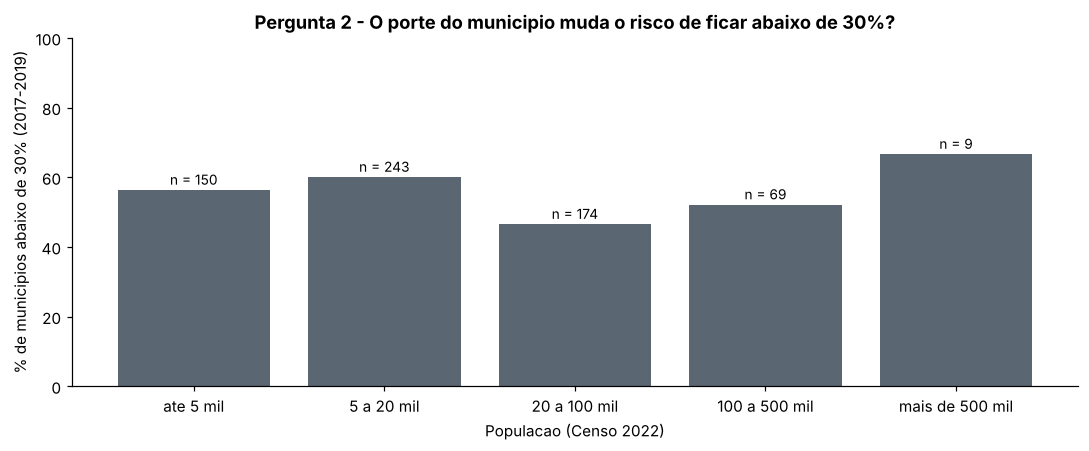

                   municipios  pc_medio_2017_2019  pc_abaixo_30
qt_populacao_2022                                              
ate 5 mil                 150                25.3          56.4
5 a 20 mil                243                26.3          60.1
20 a 100 mil              174                30.1          46.6
100 a 500 mil              69                25.3          52.2
mais de 500 mil             9                28.8          66.7


In [6]:
# Pergunta 2: municipio pequeno cumpre mais que municipio grande?
faixas = pd.cut(base['qt_populacao_2022'], bins=[0, 5000, 20000, 100000, 500000, 2e7],
                labels=['ate 5 mil', '5 a 20 mil', '20 a 100 mil', '100 a 500 mil', 'mais de 500 mil'])
tab_porte = base.groupby(faixas, observed=True).agg(
    municipios=('cd_ibge_municipio', 'size'),
    pc_medio_2017_2019=('pc_aquisicao_af_media_2017_2019', 'mean'),
    pc_abaixo_30=('st_abaixo_meta_30_2017_2019', lambda s: 100 * s.mean()))

fig, eixo = plt.subplots(figsize=(10, 4.2))
barras = eixo.bar(tab_porte.index.astype(str), tab_porte['pc_abaixo_30'], color=GRAFITE)
for barra, n in zip(barras, tab_porte['municipios']):
    eixo.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 1.5, 'n = {}'.format(n), ha='center', fontsize=9)
eixo.set_title('Pergunta 2 - O porte do municipio muda o risco de ficar abaixo de 30%?')
eixo.set_xlabel('Populacao (Censo 2022)'); eixo.set_ylabel('% de municipios abaixo de 30% (2017-2019)')
eixo.set_ylim(0, 100)
plt.tight_layout(); plt.savefig(os.path.join(PASTA_FIGURAS, 'eda_2_porte.png')); plt.show()
print(tab_porte.round(1).to_string())

**Leitura.** Em SP, o porte **sozinho** separa pouco: nas faixas com muitos municípios, a proporção abaixo
da meta fica entre 47% e 60%, sem um padrão simples. Só os 9 municípios acima de 500 mil habitantes destoam
(67% abaixo), na direção que os estudos apontam (grandes compram menos da AF). É o primeiro sinal de que
as variáveis do IBGE não bastam — confirmado no teste de robustez (seção 10).

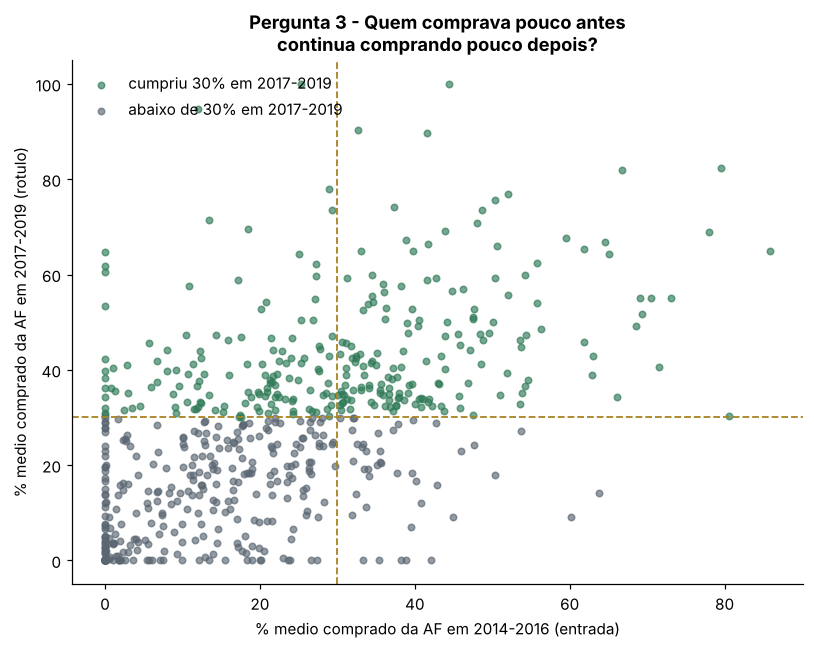

Correlacao entre as duas janelas: 0.58


In [7]:
# Pergunta 3: o comportamento passado preve o futuro?
dados_rot = base[base['st_abaixo_meta_30_2017_2019'].notna()]
fig, eixo = plt.subplots(figsize=(7.5, 6))
for classe, rotulo in [(0, 'cumpriu 30% em 2017-2019'), (1, 'abaixo de 30% em 2017-2019')]:
    parte = dados_rot[dados_rot['st_abaixo_meta_30_2017_2019'] == classe]
    eixo.scatter(parte['pc_aquisicao_af_media_2014_2016'], parte['pc_aquisicao_af_media_2017_2019'],
                 s=18, alpha=0.65, color=COR_CLASSE[classe], label=rotulo)
eixo.axhline(30, color=MILHO, ls='--', lw=1.2); eixo.axvline(30, color=MILHO, ls='--', lw=1.2)
eixo.set_title('Pergunta 3 - Quem comprava pouco antes\ncontinua comprando pouco depois?')
eixo.set_xlabel('% medio comprado da AF em 2014-2016 (entrada)')
eixo.set_ylabel('% medio comprado da AF em 2017-2019 (rotulo)')
eixo.legend(loc='upper left', frameon=False)
plt.tight_layout(); plt.savefig(os.path.join(PASTA_FIGURAS, 'eda_3_passado_futuro.png')); plt.show()
print('Correlacao entre as duas janelas: {:.2f}'.format(
    dados_rot['pc_aquisicao_af_media_2014_2016'].corr(dados_rot['pc_aquisicao_af_media_2017_2019'])))

**Leitura.** Há uma relação clara, mas com muita dispersão: há municípios que saltaram de quase zero para
acima de 30% e outros que caíram. O passado **ajuda** a prever, sem decidir sozinho. É por isso que
um modelo com várias variáveis faz sentido, e é também por isso que a métrica não vai ser perfeita.

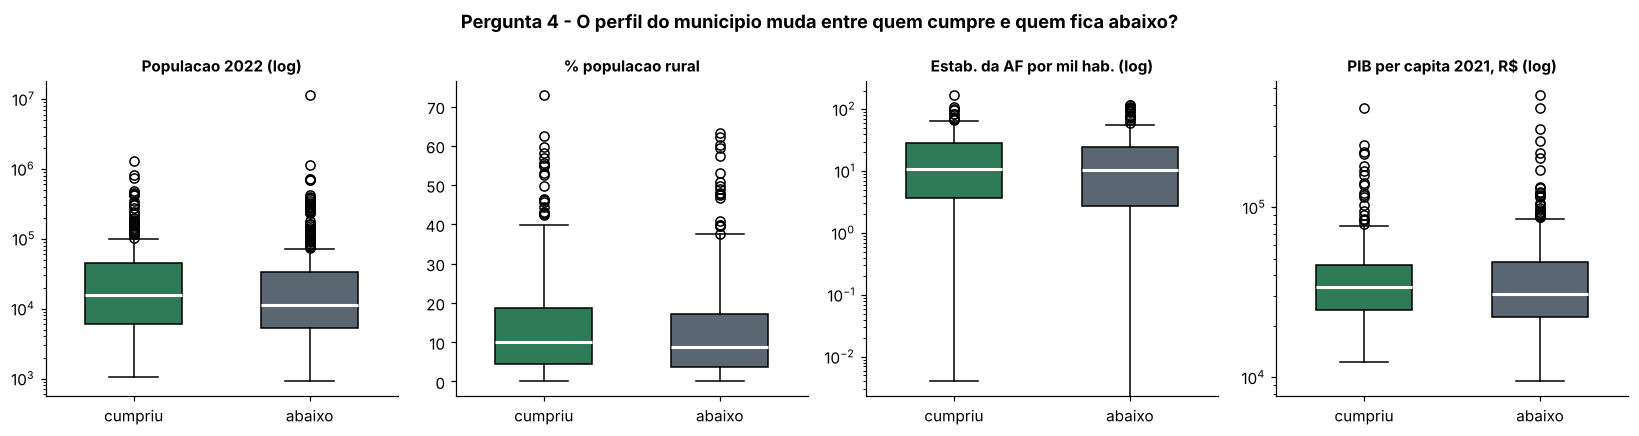

In [8]:
# Pergunta 4: o perfil do municipio (IBGE) difere entre quem cumpre e quem nao cumpre?
variaveis = [('qt_populacao_2022', 'Populacao 2022 (log)', True),
             ('pc_populacao_rural_2022', '% populacao rural', False),
             ('qt_estab_af_por_mil_hab', 'Estab. da AF por mil hab. (log)', True),
             ('vl_pib_per_capita_2021', 'PIB per capita 2021, R$ (log)', True)]
fig, eixos = plt.subplots(1, 4, figsize=(15, 4))
for eixo, (col, titulo, log) in zip(eixos, variaveis):
    grupos = [dados_rot.loc[dados_rot['st_abaixo_meta_30_2017_2019'] == c, col].dropna() for c in (0, 1)]
    caixa = eixo.boxplot(grupos, tick_labels=['cumpriu', 'abaixo'], patch_artist=True, widths=0.55,
                         medianprops={'color': 'white', 'lw': 2})
    for patch, c in zip(caixa['boxes'], (0, 1)):
        patch.set_facecolor(COR_CLASSE[c])
    if log:
        eixo.set_yscale('log')
    eixo.set_title(titulo, fontsize=10)
fig.suptitle('Pergunta 4 - O perfil do municipio muda entre quem cumpre e quem fica abaixo?', fontweight='bold')
plt.tight_layout(); plt.savefig(os.path.join(PASTA_FIGURAS, 'eda_4_perfil.png')); plt.show()

**Leitura.** As caixas se sobrepõem quase por inteiro. As medianas de quem cumpre são só um pouco maiores
em população (15,5 mil × 11,3 mil), PIB per capita (R$ 34 mil × R$ 31 mil) e % rural (10,1% × 8,8%); os
estabelecimentos da AF por mil habitantes são praticamente iguais. Nenhuma variável sozinha separa os grupos.
Conclusão da EDA para o modelo: **combinar o histórico de compra com o perfil do município**.

---
## 4. Pré-processamento e normalização Min-Max

### 4.1 Colunas descartadas

| Grupo | Colunas | Por que sai |
|---|---|---|
| Identificadores | `cd_ibge_municipio`, `nm_municipio` | um valor por linha, não generalizam (o código fica guardado para a API) |
| **Vazamento de dado** | `pc_aquisicao_af_media_2017_2019`, `vl_transferido_medio_2017_2019`, `qt_anos_sem_compra_af_2017_2019`, `qt_anos_cumpriu_30_2014_2019` | são do **mesmo período do rótulo**: seria entregar a resposta ao modelo |
| Teste fora do tempo | `pc_aquisicao_af_2022_preliminar` | reservado para a seção 10 |
| Redundantes | `qt_populacao_rural_2022`, `qt_estab_agro_total_2017`, `qt_estab_agro_familiar_2017`, `vl_area_km2` | já resumidas em `pc_populacao_rural_2022`, `qt_estab_af_por_mil_hab` e `vl_densidade_hab_km2` |

### 4.2 Transformação logarítmica

População, densidade, PIB per capita e repasse vão de centenas a milhões (São Paulo tem 11,4 milhões de
habitantes; Borá, 907). Sem o log, o Min-Max espremeria quase todos os municípios perto de zero só por
causa da capital. Usamos `log10`, que a API reproduz.

### 4.3 Ausências, codificação e Min-Max

Ausências reais são poucas (5 municípios fora do Censo Agro, 2 sem dado do FNDE em 2014–2016) e são
preenchidas com a **mediana**, guardada para a API. A região intermediária vira colunas 0/1 (**one-hot**,
CheckPoint 01). Depois, **Min-Max feito à mão**: `x' = (x − min) / (max − min)`, guardando min e max.

In [9]:
CATEGORICA = 'nm_regiao_intermediaria'
ALVO = 'st_abaixo_meta_30_2017_2019'
COLUNAS_LOG10 = ['log_populacao', 'log_densidade', 'log_pib_per_capita', 'log_transferido_medio']


def montar_features(df, janela='2014_2016', anos_meta='2011_2016'):
    # Monta as variaveis do modelo a partir da base bruta. A MESMA funcao serve
    # para a janela de treino (2014-2016) e para a janela de uso (2017-2019).
    return pd.DataFrame({
        'log_populacao': np.log10(df['qt_populacao_2022']),
        'log_densidade': np.log10(df['vl_densidade_hab_km2']),
        'pc_populacao_rural': df['pc_populacao_rural_2022'],
        'log_pib_per_capita': np.log10(df['vl_pib_per_capita_2021']),
        'estab_af_por_mil_hab': df['qt_estab_af_por_mil_hab'],
        'log_transferido_medio': np.log10(df['vl_transferido_medio_' + janela].clip(lower=1)),
        'pc_af_media_3anos': df['pc_aquisicao_af_media_' + janela],
        'qt_anos_sem_compra_af_3anos': df['qt_anos_sem_compra_af_' + janela],
        'qt_anos_cumpriu_30_6anos': df['qt_anos_cumpriu_30_' + anos_meta],
        CATEGORICA: df[CATEGORICA],
    }, index=df.index)


rotulados = base[base[ALVO].notna()].reset_index(drop=True)
y = rotulados[ALVO].astype(int)
codigos = rotulados['cd_ibge_municipio']
X_bruto = montar_features(rotulados)
print('Municipios rotulados: {} | variaveis antes do one-hot: {}'.format(len(X_bruto), X_bruto.shape[1]))
print('Ausentes por coluna:')
print(X_bruto.isna().sum()[X_bruto.isna().sum() > 0].to_string())

Municipios rotulados: 644 | variaveis antes do one-hot: 10
Ausentes por coluna:
estab_af_por_mil_hab     5
log_transferido_medio    2
pc_af_media_3anos        2


In [10]:
# ---- 4.3 Ausencias: mediana (guardada para a API) ----
NUMERICAS = [c for c in X_bruto.columns if c != CATEGORICA]
preenchimento = {c: float(X_bruto[c].median()) for c in NUMERICAS}
X_bruto[NUMERICAS] = X_bruto[NUMERICAS].fillna(preenchimento)

# ---- One-hot da regiao intermediaria ----
REGIOES = sorted(base[CATEGORICA].unique())
X = X_bruto.drop(columns=[CATEGORICA]).copy()
for regiao in REGIOES:
    X['regiao_' + regiao] = (X_bruto[CATEGORICA] == regiao).astype(int)
print('{} colunas 0/1 criadas para as regioes intermediarias:'.format(len(REGIOES)))
print('  ' + ', '.join(REGIOES))

# ---- Min-Max: x' = (x - min) / (max - min) ----
parametros_minmax = {}
for coluna in X.columns:
    minimo, maximo = float(X[coluna].min()), float(X[coluna].max())
    parametros_minmax[coluna] = {'min': minimo, 'max': maximo}
    X[coluna] = ((X[coluna] - minimo) / (maximo - minimo) if maximo > minimo else 0.0)
    X[coluna] = X[coluna].round(6)

print()
print('Base final: {} linhas x {} features'.format(*X.shape))
print('Menor valor: {:.4f} | maior valor: {:.4f} | ausentes: {}'.format(
    X.min().min(), X.max().max(), int(X.isna().sum().sum())))
print('Colunas fora de [0, 1]: {}'.format(
    [c for c in X.columns if X[c].min() < 0 or X[c].max() > 1] or 'nenhuma'))

11 colunas 0/1 criadas para as regioes intermediarias:
  ARACATUBA, ARARAQUARA, BAURU, CAMPINAS, MARILIA, PRESIDENTE_PRUDENTE, RIBEIRAO_PRETO, SAO_JOSE_DOS_CAMPOS, SAO_JOSE_DO_RIO_PRETO, SAO_PAULO, SOROCABA

Base final: 644 linhas x 20 features
Menor valor: 0.0000 | maior valor: 1.0000 | ausentes: 0
Colunas fora de [0, 1]: nenhuma


In [11]:
# Antes e depois, nas colunas de escala mais diferente
exemplo = ['log_populacao', 'pc_populacao_rural', 'estab_af_por_mil_hab', 'pc_af_media_3anos']
comparacao = pd.DataFrame({
    'min_original': [X_bruto[c].min() for c in exemplo],
    'max_original': [X_bruto[c].max() for c in exemplo],
    'min_depois': [X[c].min() for c in exemplo],
    'max_depois': [X[c].max() for c in exemplo]}, index=exemplo).round(3)
print('Efeito da normalizacao Min-Max:')
print(comparacao.to_string())

# Grava a base normalizada que acompanha a entrega (padrao de CSV da Sprint 4)
normalizada = X.copy()
normalizada.insert(0, 'cd_ibge_municipio', codigos)
normalizada[ALVO] = y
normalizada.to_csv(os.path.join(PASTA_DADOS, 'municipios_sp_base_normalizada.csv'),
                   index=False, float_format='%.6f', encoding='utf-8')
print()
print('Gravado: dados/municipios_sp_base_normalizada.csv ({} linhas x {} colunas)'.format(*normalizada.shape))

Efeito da normalizacao Min-Max:
                      min_original  max_original  min_depois  max_depois
log_populacao                2.958         7.059         0.0         1.0
pc_populacao_rural           0.000        72.960         0.0         1.0
estab_af_por_mil_hab         0.000       169.461         0.0         1.0
pc_af_media_3anos            0.000        85.830         0.0         1.0

Gravado: dados/municipios_sp_base_normalizada.csv (644 linhas x 22 colunas)


---
## 5. Divisão entre treino e teste

70% para treino e 30% para teste, **estratificado**: a proporção de municípios abaixo da meta é a mesma
nos dois lados. `random_state` fixo para o resultado ser reproduzível.

In [12]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.30, random_state=SEMENTE, stratify=y)
print('Treino: {:3d} municipios | {:3d} abaixo da meta ({:.1f}%)'.format(
    len(X_treino), int(y_treino.sum()), 100 * y_treino.mean()))
print('Teste:  {:3d} municipios | {:3d} abaixo da meta ({:.1f}%)'.format(
    len(X_teste), int(y_teste.sum()), 100 * y_teste.mean()))

Treino: 450 municipios | 247 abaixo da meta (54.9%)
Teste:  194 municipios | 106 abaixo da meta (54.6%)


---
## 6. Modelo 1 — Classificação do risco de descumprir a meta

Treinamos dois classificadores e comparamos. Se o mais complexo não superar o mais simples, fica o simples.

### 6.1 Regressão Logística

**Por que este modelo.** É o classificador mais simples que devolve uma **probabilidade**, que é o
formato que a API precisa ("72% de risco"). E é **explicável**: cada coeficiente diz para que lado a
variável empurra o risco, algo que um gestor público precisa entender antes de confiar no alerta.
`class_weight='balanced'` compensa a pequena diferença entre as classes.

In [13]:
def avaliar(nome, y_real, y_previsto, y_prob):
    # Metricas da classe 1 (abaixo da meta), que e a classe que o alerta precisa encontrar
    p, r, f, _ = precision_recall_fscore_support(y_real, y_previsto, average='binary', zero_division=0)
    auc = roc_auc_score(y_real, y_prob)
    mc = confusion_matrix(y_real, y_previsto)
    print('=' * 66); print(nome); print('=' * 66)
    print('  Precisao (abaixo da meta) .. {:.3f}'.format(p))
    print('  Recall   (abaixo da meta) .. {:.3f}'.format(r))
    print('  F1       (abaixo da meta) .. {:.3f}'.format(f))
    print('  AUC-ROC .................... {:.3f}'.format(auc))
    print()
    print('  Matriz de confusao:         previsto cumpre   previsto abaixo')
    print('    real cumpriu              {:>15d}   {:>15d}'.format(mc[0][0], mc[0][1]))
    print('    real abaixo da meta       {:>15d}   {:>15d}'.format(mc[1][0], mc[1][1]))
    print()
    print(classification_report(y_real, y_previsto, target_names=['cumpriu', 'abaixo'], digits=3))
    return {'precisao': round(float(p), 4), 'recall': round(float(r), 4),
            'f1': round(float(f), 4), 'auc': round(float(auc), 4)}


modelo_rl = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEMENTE)
modelo_rl.fit(X_treino, y_treino)
prob_rl = modelo_rl.predict_proba(X_teste)[:, 1]
pred_rl = modelo_rl.predict(X_teste)
metricas_rl = avaliar('MODELO 1A - REGRESSAO LOGISTICA', y_teste, pred_rl, prob_rl)

MODELO 1A - REGRESSAO LOGISTICA
  Precisao (abaixo da meta) .. 0.757
  Recall   (abaixo da meta) .. 0.792
  F1       (abaixo da meta) .. 0.774
  AUC-ROC .................... 0.813

  Matriz de confusao:         previsto cumpre   previsto abaixo
    real cumpriu                           61                27
    real abaixo da meta                    22                84

              precision    recall  f1-score   support

     cumpriu      0.735     0.693     0.713        88
      abaixo      0.757     0.792     0.774       106

    accuracy                          0.747       194
   macro avg      0.746     0.743     0.744       194
weighted avg      0.747     0.747     0.747       194



### 6.2 Random Forest

**Por que este modelo.** A Regressão Logística só traça uma fronteira reta. Se o risco depender de
**combinações** (por exemplo: município grande **e** sem histórico **e** com pouca agricultura familiar
local), um conjunto de árvores de decisão captura isso. Limitamos a profundidade (6) e o tamanho mínimo
da folha (5) porque a base tem só 644 municípios: árvores livres decorariam o treino.

In [14]:
modelo_rf = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=5,
                                   class_weight='balanced', random_state=SEMENTE, n_jobs=-1)
modelo_rf.fit(X_treino, y_treino)
prob_rf = modelo_rf.predict_proba(X_teste)[:, 1]
pred_rf = modelo_rf.predict(X_teste)
metricas_rf = avaliar('MODELO 1B - RANDOM FOREST', y_teste, pred_rf, prob_rf)

MODELO 1B - RANDOM FOREST
  Precisao (abaixo da meta) .. 0.761
  Recall   (abaixo da meta) .. 0.811
  F1       (abaixo da meta) .. 0.785
  AUC-ROC .................... 0.795

  Matriz de confusao:         previsto cumpre   previsto abaixo
    real cumpriu                           61                27
    real abaixo da meta                    20                86

              precision    recall  f1-score   support

     cumpriu      0.753     0.693     0.722        88
      abaixo      0.761     0.811     0.785       106

    accuracy                          0.758       194
   macro avg      0.757     0.752     0.754       194
weighted avg      0.757     0.758     0.757       194



---
## 7. Modelo 2 — Agrupamento K-Means dos municípios paulistas

**Por que este modelo.** Aqui não existe rótulo: a pergunta é "**que tipos de município existem?**".
O K-Means junta municípios parecidos em *k* grupos, olhando várias variáveis ao mesmo tempo.

**Por que não um `GROUP BY`?** Um `GROUP BY` agrupa por uma regra que **nós** escolhemos (ex.: faixa de
população). O K-Means **descobre** os grupos a partir dos dados, combinando seis variáveis de uma vez, sem
termos que inventar os cortes. (Mesma distinção que fizemos no CheckPoint 03.)

**Variáveis do perfil:** porte (log da população), densidade (log), % rural, PIB per capita (log),
estabelecimentos da agricultura familiar por mil habitantes e o **% comprado da AF em 2017–2019**
(o perfil de compra, que o dossiê pede). Todos os **645** municípios entram, inclusive os sem rótulo.

In [15]:
COLUNAS_PERFIL = ['log_populacao', 'log_densidade', 'pc_populacao_rural', 'log_pib_per_capita',
                  'estab_af_por_mil_hab', 'pc_af_media_2017_2019']

perfil_bruto = pd.DataFrame({
    'log_populacao': np.log10(base['qt_populacao_2022']),
    'log_densidade': np.log10(base['vl_densidade_hab_km2']),
    'pc_populacao_rural': base['pc_populacao_rural_2022'],
    'log_pib_per_capita': np.log10(base['vl_pib_per_capita_2021']),
    'estab_af_por_mil_hab': base['qt_estab_af_por_mil_hab'],
    'pc_af_media_2017_2019': base['pc_aquisicao_af_media_2017_2019']})

# Ausentes pela mediana; teto no percentil 99 para estab_af_por_mil_hab, senao meia duzia de
# municipios muito rurais "puxariam" um grupo so para eles (o K-Means e sensivel a extremos).
preenchimento_perfil = {c: float(perfil_bruto[c].median()) for c in COLUNAS_PERFIL}
perfil_bruto = perfil_bruto.fillna(preenchimento_perfil)
teto_af = float(perfil_bruto['estab_af_por_mil_hab'].quantile(0.99))
perfil_bruto['estab_af_por_mil_hab'] = perfil_bruto['estab_af_por_mil_hab'].clip(upper=teto_af)

minmax_perfil = {c: {'min': float(perfil_bruto[c].min()), 'max': float(perfil_bruto[c].max())}
                 for c in COLUNAS_PERFIL}
perfil = pd.DataFrame({c: (perfil_bruto[c] - minmax_perfil[c]['min']) /
                          (minmax_perfil[c]['max'] - minmax_perfil[c]['min']) for c in COLUNAS_PERFIL})
print('Base do K-Means: {} municipios x {} variaveis, todas entre {:.1f} e {:.1f}'.format(
    *perfil.shape, perfil.min().min(), perfil.max().max()))

Base do K-Means: 645 municipios x 6 variaveis, todas entre 0.0 e 1.0


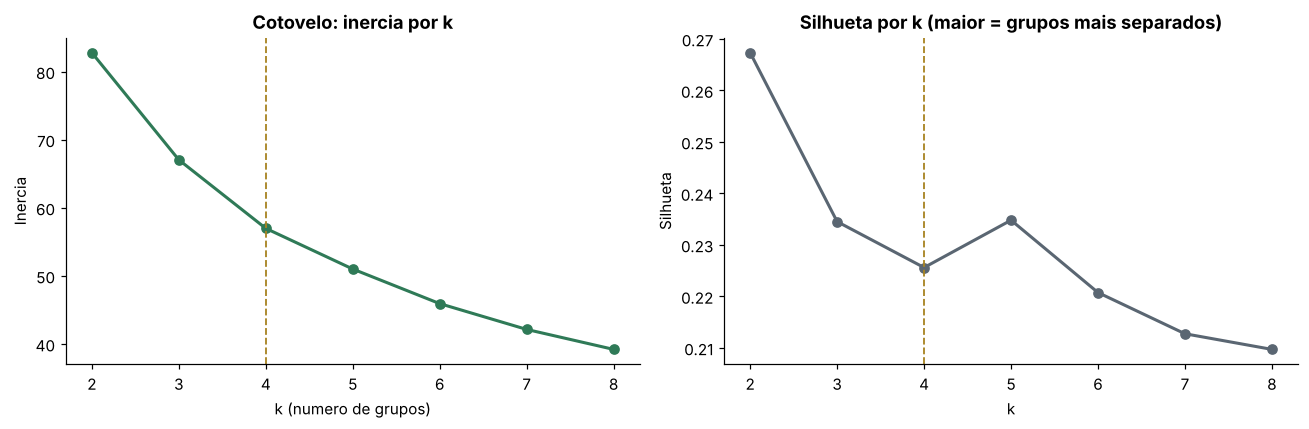

 k  inercia  silhueta
 2     82.8     0.267
 3     67.0     0.234
 4     57.0     0.226
 5     51.0     0.235
 6     45.9     0.221
 7     42.1     0.213
 8     39.2     0.210


In [16]:
# Escolha do k: metodo do cotovelo (inercia) + coeficiente de silhueta
faixa_k = range(2, 9)
inercias, silhuetas = [], []
for k in faixa_k:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEMENTE).fit(perfil)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(perfil, km.labels_))

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].plot(list(faixa_k), inercias, marker='o', color=VERDE, lw=2)
eixos[0].set_title('Cotovelo: inercia por k'); eixos[0].set_xlabel('k (numero de grupos)'); eixos[0].set_ylabel('Inercia')
eixos[1].plot(list(faixa_k), silhuetas, marker='o', color=GRAFITE, lw=2)
eixos[1].set_title('Silhueta por k (maior = grupos mais separados)'); eixos[1].set_xlabel('k'); eixos[1].set_ylabel('Silhueta')
for eixo in eixos:
    eixo.axvline(4, color=MILHO, ls='--', lw=1.2)
plt.tight_layout(); plt.savefig(os.path.join(PASTA_FIGURAS, 'kmeans_escolha_k.png')); plt.show()
print(pd.DataFrame({'k': list(faixa_k), 'inercia': np.round(inercias, 1),
                    'silhueta': np.round(silhuetas, 3)}).to_string(index=False))

**Escolha: k = 4.** O cotovelo não é nítido (comum em dados reais) e a silhueta fica entre 0,21 e 0,26 para
qualquer k: os municípios paulistas formam um **contínuo**, não ilhas separadas. Por isso decidimos pela
**utilidade**: k = 2 só separaria "urbano × resto"; com k = 4 aparecem os dois perfis que interessam ao
negócio (quem já compra e quem compra pouco), com silhueta praticamente igual. Acima de 4, os grupos novos
repetem os anteriores.

In [17]:
K_ESCOLHIDO = 4
modelo_km = KMeans(n_clusters=K_ESCOLHIDO, n_init=20, random_state=SEMENTE).fit(perfil)
base['grupo_kmeans'] = modelo_km.labels_
silhueta_km = float(silhouette_score(perfil, modelo_km.labels_))

# Leitura dos grupos na unidade original
leitura = pd.DataFrame({
    'municipios': base.groupby('grupo_kmeans').size(),
    'populacao_mediana': base.groupby('grupo_kmeans')['qt_populacao_2022'].median(),
    'densidade_mediana': base.groupby('grupo_kmeans')['vl_densidade_hab_km2'].median(),
    'pc_rural_mediano': base.groupby('grupo_kmeans')['pc_populacao_rural_2022'].median(),
    'estab_af_mil_hab': base.groupby('grupo_kmeans')['qt_estab_af_por_mil_hab'].median(),
    'pib_pc_mediano': base.groupby('grupo_kmeans')['vl_pib_per_capita_2021'].median(),
    'pc_af_2017_2019': base.groupby('grupo_kmeans')['pc_aquisicao_af_media_2017_2019'].median(),
    'pc_abaixo_30': 100 * base.groupby('grupo_kmeans')[ALVO].mean(),
    'repasse_total_mi': base.groupby('grupo_kmeans')['vl_transferido_medio_2017_2019'].sum() / 1e6})

# Nome de cada grupo por REGRA sobre os centroides (nao por numero fixo), para continuar
# valido se o K-Means for retreinado e os numeros dos grupos mudarem.
centros = pd.DataFrame(modelo_km.cluster_centers_, columns=COLUNAS_PERFIL)
nomes = {}
urbano = int(centros['log_populacao'].idxmax()); nomes[urbano] = 'URBANO_DENSO'
resto = centros.drop(index=urbano)
rural = int(resto['estab_af_por_mil_hab'].idxmax()); nomes[rural] = 'RURAL_COM_MUITA_AF'
resto = resto.drop(index=rural)
nomes[int(resto['pc_af_media_2017_2019'].idxmax())] = 'INTERIOR_JA_COMPRA_DA_AF'
nomes[int(resto['pc_af_media_2017_2019'].idxmin())] = 'INTERIOR_COMPRA_POUCO_DA_AF'
leitura.insert(0, 'perfil', leitura.index.map(nomes))
base['nm_perfil'] = base['grupo_kmeans'].map(nomes)
print('Silhueta com k = {}: {:.3f}'.format(K_ESCOLHIDO, silhueta_km))
print(leitura.round(1).to_string())

Silhueta com k = 4: 0.226
                                   perfil  municipios  populacao_mediana  densidade_mediana  pc_rural_mediano  estab_af_mil_hab  pib_pc_mediano  pc_af_2017_2019  pc_abaixo_30  repasse_total_mi
grupo_kmeans                                                                                                                                                                                    
0                INTERIOR_JA_COMPRA_DA_AF         172            13732.0               34.0              10.5              11.4         33196.8             41.8           4.7              59.6
1             INTERIOR_COMPRA_POUCO_DA_AF         209             8833.0               33.3               9.6              11.3         27503.8             12.1          98.1              47.0
2                      RURAL_COM_MUITA_AF         109             4138.0               16.3              28.8              48.0         25989.1             29.8          50.5              13.5
3        

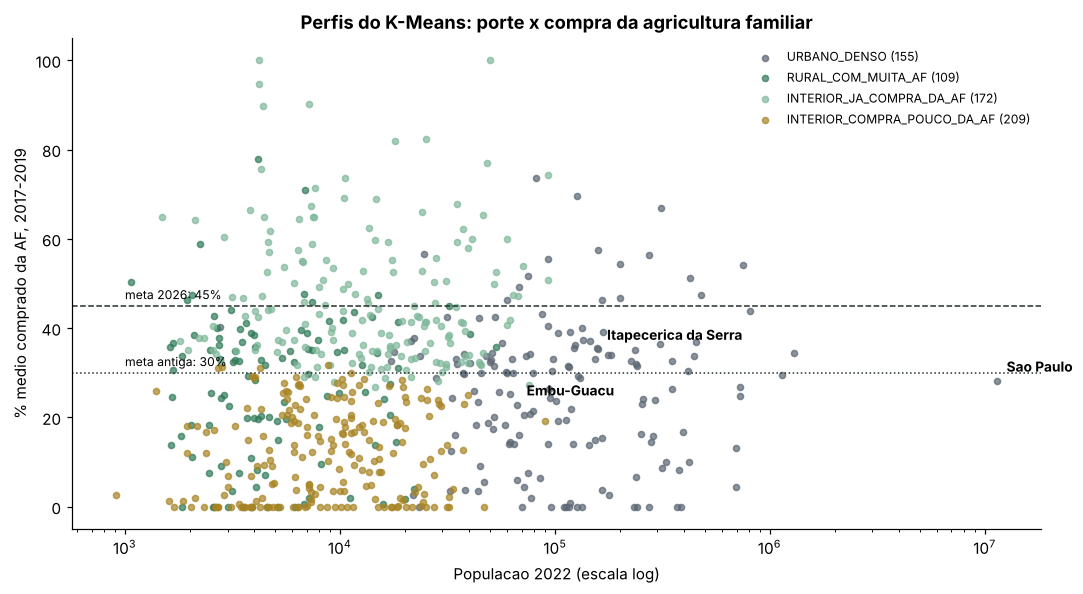

In [18]:
# Mapa dos perfis em duas dimensoes que o gestor entende: porte x % comprado da AF
cores_perfil = {'URBANO_DENSO': GRAFITE, 'RURAL_COM_MUITA_AF': VERDE,
                'INTERIOR_JA_COMPRA_DA_AF': '#7FB89A', 'INTERIOR_COMPRA_POUCO_DA_AF': MILHO}
fig, eixo = plt.subplots(figsize=(10, 5.5))
for nome, cor in cores_perfil.items():
    parte = base[base['nm_perfil'] == nome]
    eixo.scatter(parte['qt_populacao_2022'], parte['pc_aquisicao_af_media_2017_2019'], s=16, alpha=0.7,
                 color=cor, label='{} ({})'.format(nome, len(parte)))
for cod, rotulo in [(3550308, 'Sao Paulo'), (3515103, 'Embu-Guacu'), (3522208, 'Itapecerica da Serra')]:
    linha = base[base['cd_ibge_municipio'] == cod].iloc[0]
    eixo.annotate(rotulo, (linha['qt_populacao_2022'], linha['pc_aquisicao_af_media_2017_2019']),
                  xytext=(6, 6), textcoords='offset points', fontsize=9, fontweight='bold')
eixo.set_xscale('log'); eixo.axhline(30, color='#24302B', ls=':', lw=1); eixo.axhline(45, color='#24302B', ls='--', lw=1)
eixo.text(1000, 46.5, 'meta 2026: 45%', fontsize=8); eixo.text(1000, 31.5, 'meta antiga: 30%', fontsize=8)
eixo.set_xlabel('Populacao 2022 (escala log)'); eixo.set_ylabel('% medio comprado da AF, 2017-2019')
eixo.set_title('Perfis do K-Means: porte x compra da agricultura familiar')
eixo.legend(frameon=False, fontsize=8, loc='upper right')
plt.tight_layout(); plt.savefig(os.path.join(PASTA_FIGURAS, 'kmeans_perfis.png')); plt.show()

**Leitura dos perfis em linguagem de negócio** (os números exatos estão na tabela acima):

| Perfil | Quem é | O que o ColheAí oferece |
|---|---|---|
| `URBANO_DENSO` | cidades grandes e densas, quase sem zona rural e com pouca agricultura familiar por habitante; concentram a maior parte do repasse | **cliente prioritário**: muito dinheiro, pouca oferta local. Precisa do **mapa de safra regional** e de chamadas alinhadas à sazonalidade. É o perfil de São Paulo. |
| `INTERIOR_COMPRA_POUCO_DA_AF` | interior de porte pequeno/médio com compra muito baixa da AF | **cliente de alto risco**: tem agricultor por perto, mas não converte em compra. Alerta de risco + apoio à chamada pública. |
| `INTERIOR_JA_COMPRA_DA_AF` | interior parecido, mas que já compra perto ou acima da meta antiga | cliente de **manutenção**: precisa subir de 30% para 45%; painel da meta. |
| `RURAL_COM_MUITA_AF` | municípios pequenos e muito rurais, com muitos estabelecimentos da AF | **fonte de oferta**: seus agricultores podem abastecer os grandes centros da região. |

---
## 8. Comparação e avaliação

In [19]:
comparativo = pd.DataFrame({'Regressao Logistica': metricas_rl, 'Random Forest': metricas_rf}).T
comparativo.columns = ['Precisao', 'Recall', 'F1', 'AUC-ROC']

# Validacao cruzada (5 partes) na base inteira: mostra se o resultado depende da sorte do sorteio
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
for nome, modelo in [('Regressao Logistica', modelo_rl), ('Random Forest', modelo_rf)]:
    auc_cv = cross_val_score(modelo, X, y, cv=cv, scoring='roc_auc')
    f1_cv = cross_val_score(modelo, X, y, cv=cv, scoring='f1')
    comparativo.loc[nome, 'AUC (CV 5x)'] = '{:.3f} +/- {:.3f}'.format(auc_cv.mean(), auc_cv.std())
    comparativo.loc[nome, 'F1 (CV 5x)'] = '{:.3f} +/- {:.3f}'.format(f1_cv.mean(), f1_cv.std())
print(comparativo.to_string())
print()
mc_rl, mc_rf = confusion_matrix(y_teste, pred_rl), confusion_matrix(y_teste, pred_rf)
print('Em linguagem de negocio, sobre os {} municipios de teste:'.format(len(y_teste)))
print('  Logistica ..... {:2d} municipios em risco NAO alertados | {:2d} alertas falsos'.format(mc_rl[1][0], mc_rl[0][1]))
print('  Random Forest . {:2d} municipios em risco NAO alertados | {:2d} alertas falsos'.format(mc_rf[1][0], mc_rf[0][1]))

                     Precisao  Recall      F1  AUC-ROC      AUC (CV 5x)       F1 (CV 5x)
Regressao Logistica    0.7568  0.7925  0.7742   0.8129  0.793 +/- 0.027  0.743 +/- 0.048
Random Forest          0.7611  0.8113  0.7854   0.7953  0.787 +/- 0.037  0.754 +/- 0.041

Em linguagem de negocio, sobre os 194 municipios de teste:
  Logistica ..... 22 municipios em risco NAO alertados | 27 alertas falsos
  Random Forest . 20 municipios em risco NAO alertados | 27 alertas falsos


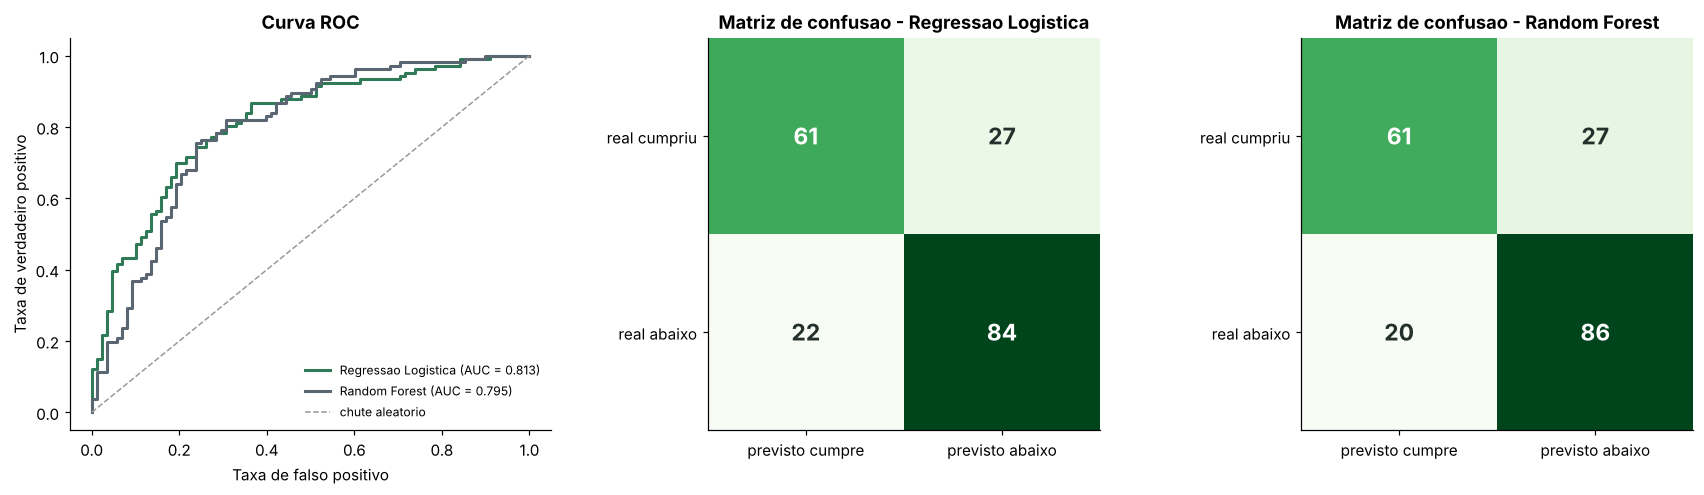

In [20]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 4.6))
for prob, nome, cor in [(prob_rl, 'Regressao Logistica', VERDE), (prob_rf, 'Random Forest', GRAFITE)]:
    fpr, tpr, _ = roc_curve(y_teste, prob)
    eixos[0].plot(fpr, tpr, color=cor, lw=2, label='{} (AUC = {:.3f})'.format(nome, roc_auc_score(y_teste, prob)))
eixos[0].plot([0, 1], [0, 1], color='#999999', ls='--', lw=1, label='chute aleatorio')
eixos[0].set_title('Curva ROC'); eixos[0].set_xlabel('Taxa de falso positivo'); eixos[0].set_ylabel('Taxa de verdadeiro positivo')
eixos[0].legend(loc='lower right', frameon=False, fontsize=8)

for eixo, mc, nome in [(eixos[1], mc_rl, 'Regressao Logistica'), (eixos[2], mc_rf, 'Random Forest')]:
    eixo.imshow(mc, cmap='Greens')
    for i in range(2):
        for j in range(2):
            eixo.text(j, i, mc[i][j], ha='center', va='center', fontsize=15, fontweight='bold',
                      color='white' if mc[i][j] > mc.max() / 2 else '#24302B')
    eixo.set_xticks([0, 1]); eixo.set_xticklabels(['previsto cumpre', 'previsto abaixo'])
    eixo.set_yticks([0, 1]); eixo.set_yticklabels(['real cumpriu', 'real abaixo'])
    eixo.set_title('Matriz de confusao - ' + nome)
plt.tight_layout(); plt.savefig(os.path.join(PASTA_FIGURAS, 'avaliacao_classificacao.png')); plt.show()

**Conclusão da comparação — empate técnico, e fica o modelo simples.** Os dois modelos ficam muito
próximos no teste e, principalmente, na validação cruzada (diferenças menores que o desvio-padrão entre as
partes). O Random Forest **não supera** a Regressão Logística de forma consistente, então não há motivo
para carregar a complexidade extra.

**Modelo escolhido para a API: Regressão Logística.** Além do empate, ela é explicável por coeficientes:
podemos dizer ao gestor **por que** o município foi marcado como risco. É a mesma régua que usamos no
challenge, aplicada com honestidade ao contrário: lá o Random Forest ganhou com folga e foi para a API;
aqui não ganhou, então não vai.

**Por que F1 e AUC, e não acurácia.** Com 55% dos municípios abaixo da meta, chutar "abaixo" para todos já
daria 55% de acurácia sem servir para nada. O F1 olha a classe que o alerta precisa encontrar (precisão
e recall juntos) e o AUC mede se o modelo **ordena** bem o risco, que é o uso real (priorizar quem abordar).

**Avaliação do K-Means.** Silhueta de cerca de 0,23 (grupos com sobreposição, esperado num contínuo de
municípios). O critério que vale para agrupamento sem rótulo é se os grupos **fazem sentido e mudam a
ação**: a tabela da seção 7 mostra que sim. O dado de negócio mais forte é a concentração do dinheiro: os
155 municípios `URBANO_DENSO` somam cerca de **79% do repasse** do estado (R$ 460 mi de R$ 580 mi por ano em
2017–2019). (A diferença de "% abaixo de 30%" entre os perfis é esperada, porque o % comprado da AF é uma
das seis variáveis do agrupamento; não a usamos como prova de qualidade.)

---
## 9. Quais variáveis pesam no risco

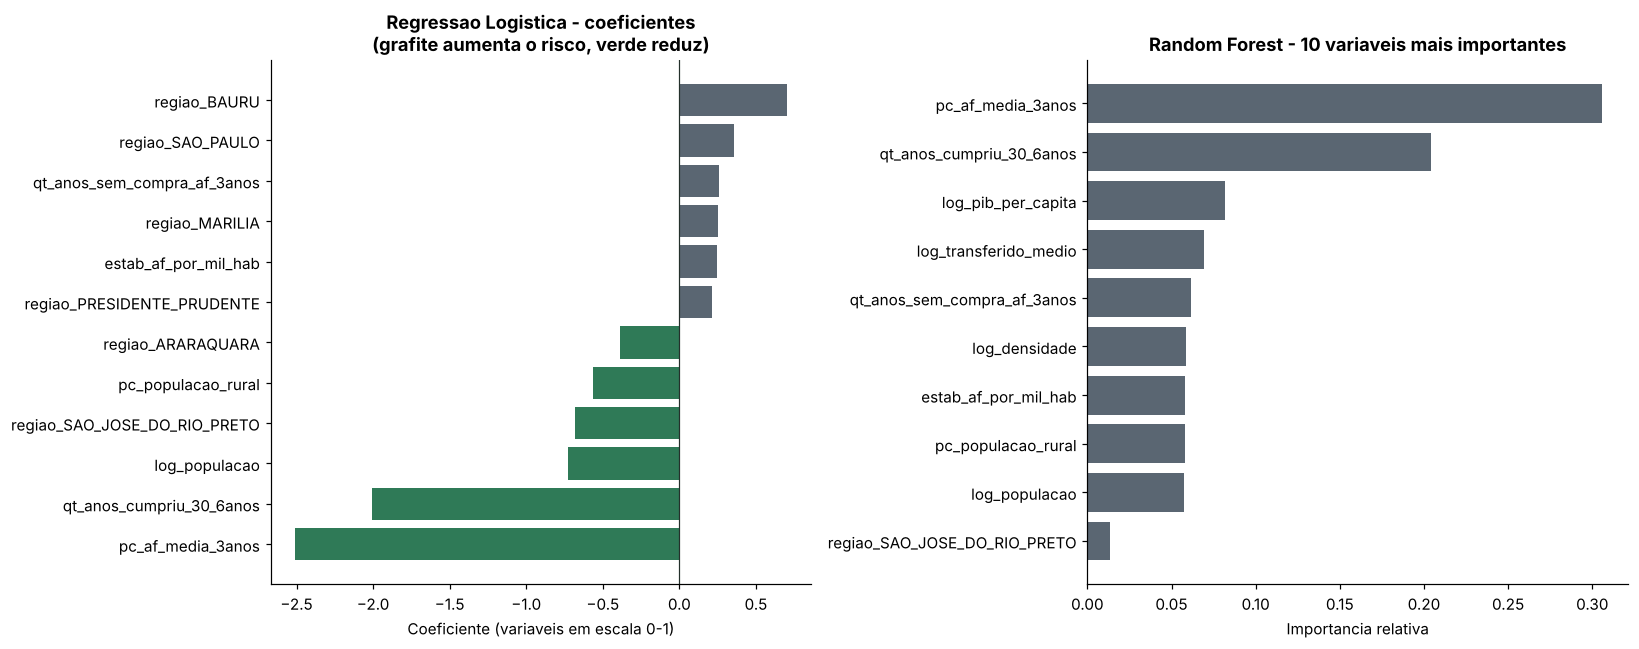

Coeficientes da Regressao Logistica (sem as regioes):
pc_af_media_3anos             -2.509
qt_anos_cumpriu_30_6anos      -2.010
log_populacao                 -0.729
pc_populacao_rural            -0.564
log_pib_per_capita            -0.283
log_transferido_medio         -0.198
log_densidade                 -0.046
estab_af_por_mil_hab           0.246
qt_anos_sem_compra_af_3anos    0.256


In [21]:
coeficientes = pd.Series(modelo_rl.coef_[0], index=X.columns).sort_values()
importancias = pd.Series(modelo_rf.feature_importances_, index=X.columns).sort_values()

fig, eixos = plt.subplots(1, 2, figsize=(15, 6))
topo = pd.concat([coeficientes.head(6), coeficientes.tail(6)])
eixos[0].barh(topo.index, topo.values, color=[VERDE if v < 0 else GRAFITE for v in topo.values])
eixos[0].axvline(0, color='#24302B', lw=0.8)
eixos[0].set_title('Regressao Logistica - coeficientes\n(grafite aumenta o risco, verde reduz)')
eixos[0].set_xlabel('Coeficiente (variaveis em escala 0-1)')
topo_rf = importancias.tail(10)
eixos[1].barh(topo_rf.index, topo_rf.values, color=GRAFITE)
eixos[1].set_title('Random Forest - 10 variaveis mais importantes'); eixos[1].set_xlabel('Importancia relativa')
plt.tight_layout(); plt.savefig(os.path.join(PASTA_FIGURAS, 'importancia_variaveis.png')); plt.show()
print('Coeficientes da Regressao Logistica (sem as regioes):')
print(coeficientes[[c for c in coeficientes.index if not c.startswith('regiao_')]].round(3).to_string())

**O que o modelo aprendeu, em linguagem de produto** (sinais lidos dos coeficientes acima):

| Variável | Leitura |
|---|---|
| `pc_af_media_3anos` e `qt_anos_cumpriu_30_6anos` | **o histórico é o sinal mais forte**: quem já comprava da agricultura familiar tende a continuar comprando, e o risco cai. |
| `qt_anos_sem_compra_af_3anos` | anos com **zero** compra da AF aumentam o risco: é o município que nem chega a fazer a chamada pública. |
| `log_populacao` e `pc_populacao_rural` | **com o histórico já considerado**, municípios maiores e mais rurais têm risco um pouco menor. Hipótese (não testada aqui): prefeituras maiores têm mais estrutura de compras e nutricionista. |
| `estab_af_por_mil_hab` | peso pequeno e sinal positivo. Ela mede quase a mesma coisa que `pc_populacao_rural` (municípios rurais têm mais estabelecimentos), e quando duas variáveis andam juntas a regressão divide o efeito entre elas. **Não deve ser lida isoladamente.** |
| `regiao_*` | capturam diferenças regionais (estrutura de assistência técnica, cooperativas, logística). Não usamos como "regra", só como ajuste. |

Nada aqui é arbitrário: são variáveis que uma prefeitura **conhece antes** do período que está sendo
previsto. Esse é o tipo de explicação que transforma a probabilidade em ação no painel do ColheAí.

---
## 10. Teste de robustez — de onde vem o poder do modelo

Três perguntas antes de confiar no resultado:

1. **O modelo depende de um grupo só de variáveis?** Treinamos com só IBGE, só histórico e tudo.
2. **O resultado é sorte do sorteio?** Já respondido na seção 8 (validação cruzada com desvio pequeno).
3. **Funciona em outro período?** *Teste fora do tempo:* aplicamos o modelo treinado à janela 2017–2019 e
   conferimos contra 2022 (preliminar), que o modelo nunca viu.

In [22]:
GRUPO_IBGE = ['log_populacao', 'log_densidade', 'pc_populacao_rural', 'log_pib_per_capita',
              'estab_af_por_mil_hab', 'log_transferido_medio'] + [c for c in X.columns if c.startswith('regiao_')]
GRUPO_HISTORICO = ['pc_af_media_3anos', 'qt_anos_sem_compra_af_3anos', 'qt_anos_cumpriu_30_6anos']


def treinar_com(colunas, cenario):
    modelo = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEMENTE)
    auc = cross_val_score(modelo, X[colunas], y, cv=cv, scoring='roc_auc')
    f1 = cross_val_score(modelo, X[colunas], y, cv=cv, scoring='f1')
    return {'cenario': cenario, 'variaveis': len(colunas),
            'AUC (CV)': round(auc.mean(), 3), 'F1 (CV)': round(f1.mean(), 3)}


robustez = pd.DataFrame([
    treinar_com(list(X.columns), 'Todas as variaveis'),
    treinar_com(GRUPO_IBGE, 'Somente perfil do municipio (IBGE + repasse)'),
    treinar_com(GRUPO_HISTORICO, 'Somente historico de compra (FNDE)'),
]).set_index('cenario')
print(robustez.to_string())

                                              variaveis  AUC (CV)  F1 (CV)
cenario                                                                   
Todas as variaveis                                   20     0.793    0.743
Somente perfil do municipio (IBGE + repasse)         17     0.599    0.580
Somente historico de compra (FNDE)                    3     0.790    0.745


In [23]:
# Teste fora do tempo: mesmas variaveis, calculadas na janela 2017-2019, contra o resultado de 2022
def preparar(df_bruto):
    # Repete EXATAMENTE o pre-processamento do treino (mediana, one-hot, Min-Max salvos)
    df = df_bruto.copy()
    df[NUMERICAS] = df[NUMERICAS].fillna(preenchimento)
    saida = df.drop(columns=[CATEGORICA])
    for regiao in REGIOES:
        saida['regiao_' + regiao] = (df[CATEGORICA] == regiao).astype(int)
    for coluna, p in parametros_minmax.items():
        saida[coluna] = (saida[coluna] - p['min']) / (p['max'] - p['min']) if p['max'] > p['min'] else 0.0
    return saida[list(X.columns)]


com_2022 = base[base['pc_aquisicao_af_2022_preliminar'].notna() & base['pc_aquisicao_af_media_2017_2019'].notna()]
X_2022 = preparar(montar_features(com_2022, janela='2017_2019', anos_meta='2014_2019'))
y_2022 = (com_2022['pc_aquisicao_af_2022_preliminar'] < 30).astype(int)
prob_2022 = modelo_rl.predict_proba(X_2022)[:, 1]
pred_2022 = (prob_2022 >= 0.5).astype(int)
p22, r22, f22, _ = precision_recall_fscore_support(y_2022, pred_2022, average='binary')
print('Teste fora do tempo (entrada 2017-2019 -> resultado 2022 preliminar)')
print('  municipios ........ {}  | abaixo de 30% em 2022: {:.1f}%'.format(len(y_2022), 100 * y_2022.mean()))
print('  AUC-ROC ........... {:.3f}'.format(roc_auc_score(y_2022, prob_2022)))
print('  F1 ................ {:.3f}  (precisao {:.3f} | recall {:.3f})'.format(f22, p22, r22))

Teste fora do tempo (entrada 2017-2019 -> resultado 2022 preliminar)
  municipios ........ 602  | abaixo de 30% em 2022: 46.0%
  AUC-ROC ........... 0.763
  F1 ................ 0.660  (precisao 0.692 | recall 0.632)


**Interpretação.**

- **Só o perfil do IBGE prevê pouco** (AUC de 0,60, pouco acima do acaso). As características do
  município explicam pouco **sozinhas**: o que decide é gestão, e gestão aparece no histórico. Isso confirma
  o que a EDA mostrou e o que o dossiê diz ("o gargalo é de gestão").
- **Só o histórico chega praticamente ao mesmo resultado** do modelo completo (0,790 × 0,793). O sinal está
  concentrado no histórico, mas **isso não é vazamento**: o histórico é de 2014–2016, anterior ao período do
  rótulo, e estaria disponível na hora de prever. Significa que o comportamento de compra **persiste**.
  Mantivemos as variáveis do IBGE porque deixam o modelo usável para explicar o perfil e não pioram a métrica.
- **Fora do tempo o modelo continua útil, com queda esperada**: o período mudou (pandemia no meio, 2022
  preliminar e com distorções), mas o modelo ainda ordena o risco bem acima do acaso. Em produção, o
  modelo deve ser **retreinado** quando o FNDE consolidar 2022–2025.

---
## 11. Discussão dos resultados

### O que deu certo
- **Dado 100% público e real**, cruzando FNDE e IBGE pelo código do município, com problemas de qualidade
  encontrados e tratados às claras (homônimos, 2022 preliminar, pandemia).
- **Métricas honestas.** AUC por volta de 0,8 e F1 entre 0,74 e 0,77 são realistas para um fenômeno de gestão
  pública. No challenge (base sintética) tivemos AUC de 0,996 e dissemos que era otimista; aqui não há esse
  otimismo para declarar.
- **Desenho temporal** (passado prevê futuro) e **teste fora do tempo**: o modelo responde à pergunta que
  a prefeitura realmente faz, "vou cumprir a próxima meta?".
- **Dois modelos complementares**: a classificação diz **quanto** risco; o K-Means diz **que tipo** de
  município é e **qual abordagem** comercial usar.

### Limitações, declaradas abertamente
1. **O rótulo mede 30%, não 45%.** Os dados vão até 2022 e a meta de 45% só vale a partir de 2026. O risco
   calculado é, portanto, um **piso**: quem está em risco para 30% está em risco maior para 45%.
2. **Base pequena** (644 municípios rotulados): por isso preferimos o modelo simples e validamos com
   validação cruzada.
3. **O FNDE e o TCM divergem para São Paulo** (FNDE: 43% em 2018 e 33% em 2019; TCM: 26,2% e 26,8%). Usamos
   o FNDE, que é a fonte única para todos os municípios; a divergência fica registrada.
4. **Faltam variáveis de gestão** (existência de nutricionista, número de chamadas publicadas, cooperativas
   ativas). Elas explicariam o que o IBGE não explica, e o ColheAí passa a gerá-las com o uso da plataforma.
5. **K-Means com silhueta modesta**: os perfis são úteis para decidir a abordagem, não fronteiras rígidas.

---
## 12. Serialização dos modelos para a API

Cada arquivo leva **o modelo e tudo o que é preciso para usá-lo**: a ordem das colunas, os parâmetros de
Min-Max, as medianas de preenchimento, as regiões do one-hot e as métricas. Sem isso, a API normalizaria
um município novo com mínimos e máximos diferentes e a previsão sairia errada **sem nenhum erro visível**.

O pacote do modelo de risco leva também a **tabela dos 645 municípios** já com as variáveis da janela
2017–2019, para a API responder por código IBGE (`GET /api/municipio/<cd_ibge>`) sem acessar banco.

In [24]:
EQUIPE = 'Since Young - 1TDSPV-2026 - Artur Bianchini Esteves RM569450 | Joao Vitor Oliveira Fontenele Martins RM570783'

# Tabela de uso: variaveis de HOJE (janela 2017-2019) para cada municipio, ja na forma de entrada da API
uso = montar_features(base, janela='2017_2019', anos_meta='2014_2019')
uso[NUMERICAS] = uso[NUMERICAS].fillna(preenchimento)
uso.insert(0, 'nm_municipio', base['nm_municipio'])
uso['nm_perfil'] = base['nm_perfil']
uso['pc_af_media_2017_2019'] = base['pc_aquisicao_af_media_2017_2019']
municipios = {int(cod): {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else
                             (int(v) if isinstance(v, (np.integer,)) else v))
                         for k, v in linha.items()}
              for cod, linha in zip(base['cd_ibge_municipio'], uso.to_dict('records'))}

pacote_risco = {
    'modelo': modelo_rl,
    'colunas': list(X.columns),
    'parametros_minmax': parametros_minmax,
    'metricas': {**metricas_rl, 'auc_fora_do_tempo_2022': round(float(roc_auc_score(y_2022, prob_2022)), 4)},
    'versao': '1.0',
    'equipe': EQUIPE,
    'tipo': 'classificacao - Regressao Logistica',
    'rotulo': 'media de compra da agricultura familiar abaixo de 30% na janela seguinte',
    'colunas_entrada': NUMERICAS + [CATEGORICA],
    'colunas_log10': COLUNAS_LOG10,
    'regioes': REGIOES,
    'valores_preenchimento': preenchimento,
    'municipios': municipios,
    'fontes': 'FNDE PNAE Dados da Agricultura Familiar 2011-2022; IBGE Censo 2022, PIB 2021, Censo Agro 2017 (acesso 17/11/2026)',
    'versao_sklearn': sklearn.__version__,
}
pacote_kmeans = {
    'modelo': modelo_km,
    'colunas': COLUNAS_PERFIL,
    'parametros_minmax': minmax_perfil,
    'metricas': {'silhueta': round(silhueta_km, 4), 'k': K_ESCOLHIDO, 'inercia': round(float(modelo_km.inertia_), 4)},
    'versao': '1.0',
    'equipe': EQUIPE,
    'tipo': 'agrupamento - K-Means',
    'nomes_grupos': {int(k): v for k, v in nomes.items()},
    'valores_preenchimento': preenchimento_perfil,
    'teto_estab_af_por_mil_hab': teto_af,
    'perfil_medio': leitura.drop(columns=['perfil']).round(2).to_dict('index'),
    'versao_sklearn': sklearn.__version__,
}
caminho_risco = os.path.join(PASTA_MODELOS, 'modelo_risco_meta.joblib')
caminho_km = os.path.join(PASTA_MODELOS, 'modelo_perfil_kmeans.joblib')
joblib.dump(pacote_risco, caminho_risco)
joblib.dump(pacote_kmeans, caminho_km)
for caminho in (caminho_risco, caminho_km):
    print('Gravado: {} ({:.1f} KB)'.format(caminho, os.path.getsize(caminho) / 1024))

Gravado: ../modelos/modelo_risco_meta.joblib (84.8 KB)
Gravado: ../modelos/modelo_perfil_kmeans.joblib (5.1 KB)


### Teste da serialização

Antes de levar os arquivos para a API: eles voltam do disco e preveem igual ao modelo em memória?

In [25]:
risco_rec = joblib.load(caminho_risco)
km_rec = joblib.load(caminho_km)

iguais_risco = np.allclose(risco_rec['modelo'].predict_proba(X_teste)[:, 1], prob_rl)
iguais_km = bool((km_rec['modelo'].predict(perfil) == modelo_km.labels_).all())
print('Risco: probabilidades identicas apos recarregar ...', bool(iguais_risco))
print('K-Means: grupos identicos apos recarregar ..........', iguais_km)
print('Chaves do pacote de risco:', sorted(risco_rec.keys()))
print()

# Simulacao do que a API vai fazer para os tres municipios do banco do ColheAi
X_uso = preparar(montar_features(base, janela='2017_2019', anos_meta='2014_2019'))
base['prob_risco_hoje'] = risco_rec['modelo'].predict_proba(X_uso)[:, 1]
print('Municipios do banco do ColheAi, pontuados com o historico 2017-2019:')
print(base.loc[base['cd_ibge_municipio'].isin([3550308, 3515103, 3522208]),
               ['cd_ibge_municipio', 'nm_municipio', 'pc_aquisicao_af_media_2017_2019',
                'prob_risco_hoje', 'nm_perfil']].round(3).to_string(index=False))

Risco: probabilidades identicas apos recarregar ... True
K-Means: grupos identicos apos recarregar .......... True
Chaves do pacote de risco: ['colunas', 'colunas_entrada', 'colunas_log10', 'equipe', 'fontes', 'metricas', 'modelo', 'municipios', 'parametros_minmax', 'regioes', 'rotulo', 'tipo', 'valores_preenchimento', 'versao', 'versao_sklearn']

Municipios do banco do ColheAi, pontuados com o historico 2017-2019:
 cd_ibge_municipio         nm_municipio  pc_aquisicao_af_media_2017_2019  prob_risco_hoje    nm_perfil
           3515103           EMBU_GUACU                            22.88            0.611 URBANO_DENSO
           3522208 ITAPECERICA_DA_SERRA                            35.33            0.503 URBANO_DENSO
           3550308            SAO_PAULO                            28.21            0.362 URBANO_DENSO


---
## 13. A ponte com a aplicação real

A API Flask (`api/api_colheai_ia.py`) carrega os dois arquivos `.joblib` e expõe:

| Rota | O que faz | Quem usa |
|---|---|---|
| `GET /` | health check (responde 200 mesmo se um modelo falhar) | Render |
| `GET /api/status` | versão, métricas e campos aceitos dos **dois** modelos | professor, monitoramento |
| `POST /api/prever-risco` | recebe as variáveis de um município e devolve probabilidade + faixa de risco | qualquer cliente |
| `POST /api/perfil-municipio` | recebe as variáveis de perfil e devolve o grupo do K-Means | qualquer cliente |
| `GET /api/municipio/<cd_ibge>` | busca o município pelo código IBGE e devolve **os dois** resultados | front React (painel da meta) |

**Como as peças do ColheAí conversam (Stack de IA da Aula 11):**

| Camada | Peça | Papel |
|---|---|---|
| Interface | front React (Vercel) | painel da meta da EEx |
| Backend de negócio | API Java (Spring Boot) + Oracle | chamadas, propostas, regra dos R$ 40 mil, `cd_ibge_municipio` da EEx |
| Sistema de IA | **esta API Flask** + modelos `.joblib` | risco e perfil do município |

A API Java guarda o `cd_ibge_municipio` de cada EEx (`T_CLH_ENTIDADE_EXECUTORA`). Com esse código, o front
chama `GET /api/municipio/3550308` e mostra, ao lado do painel da meta, o risco calculado pelo modelo.
Um chatbot (Watson Assistant + Node-RED, como nos CheckPoints) poderia consumir a mesma rota para responder
"qual o risco do meu município?" no Telegram: a API não muda, só ganha mais um cliente.

### Referências
FUNDO NACIONAL DE DESENVOLVIMENTO DA EDUCAÇÃO (FNDE). **PNAE: Dados da Agricultura Familiar**. Brasília: FNDE,
2026. Disponível em: https://www.gov.br/fnde/pt-br/acesso-a-informacao/acoes-e-programas/programas/pnae/consultas/pnae-dados-da-agricultura-familiar. Acesso em: 17 nov. 2026.

INSTITUTO BRASILEIRO DE GEOGRAFIA E ESTATÍSTICA (IBGE). **Sistema IBGE de Recuperação Automática – SIDRA**:
tabelas 4714, 9923, 5938, 6579 e 6778. Rio de Janeiro: IBGE, 2026. Disponível em: https://sidra.ibge.gov.br. Acesso em: 17 nov. 2026.

BRASIL. **Lei nº 15.226, de 30 de setembro de 2025**. Altera a Lei nº 11.947/2009 (45% para a agricultura familiar).

PEDREGOSA, F. et al. Scikit-learn: Machine Learning in Python. **Journal of Machine Learning Research**, v. 12, p. 2825-2830, 2011.

PALLETS. **Flask Documentation**. 2026. Disponível em: https://flask.palletsprojects.com. Acesso em: 17 nov. 2026.